In [ ]:
from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get("llama-benchmark"))

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_id = "meta-llama/Llama-3.2-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_id)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(128256, 3072)
    (layers): ModuleList(
      (0-27): 28 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=3072, out_features=3072, bias=False)
          (k_proj): Linear(in_features=3072, out_features=1024, bias=False)
          (v_proj): Linear(in_features=3072, out_features=1024, bias=False)
          (o_proj): Linear(in_features=3072, out_features=3072, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=3072, out_features=8192, bias=False)
          (up_proj): Linear(in_features=3072, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=3072, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((3072,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((3072,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((3072,), eps=1e-05)
    (

In [ ]:
print("Parameters:", model.num_parameters())
print("Layers:", model.config.num_hidden_layers)
print("Hidden size:", model.config.hidden_size)
print("Query heads:", model.config.num_attention_heads)
print("KV heads:", model.config.num_key_value_heads)
print("Head dimension:", model.config.head_dim)

Parameters: 3212749824
Layers: 28
Hidden size: 3072
Query heads: 24
KV heads: 8
Head dimension: 128


In [ ]:
prompt = "The cat sat on the "

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100
    )

print(tokenizer.decode(outputs[0], skip_special_tokens=True))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


The cat sat on the 8th floor, but it was still a long way to the ground. The cat's owner was worried that the cat would fall off the balcony and get hurt. To prevent this, the cat's owner decided to put a safety net under the balcony. However, the cat's owner didn't have a safety net, so they decided to put a makeshift safety net using a piece of cloth. They tied the cloth to the railing of the balcony with a rope. The cat was still a long way


In [ ]:
import time
import matplotlib.pyplot as plt

sequence_lengths = [32, 64, 128, 256, 512, 1024, 2048, 4096, 8192]

latencies = []

# 3 trials to try accounting for some of the measurement noise
for length in sequence_lengths:

    trial_latencies = []

    for trial in range(3):

        with torch.no_grad():

            prefill = model(**inputs, use_cache=True)
            past_key_values = prefill.past_key_values
            next_token = prefill.logits[:, -1, :].argmax(dim=-1, keepdim=True)
            attention_mask = inputs["attention_mask"]

            step_latencies = []

            for i in range(length - 1):

                attention_mask = torch.cat(
                    [attention_mask, torch.ones_like(attention_mask[:, :1])],
                    dim=1
                )

                if torch.cuda.is_available():
                    torch.cuda.synchronize()

                start = time.perf_counter()

                outputs = model(
                    input_ids=next_token,
                    attention_mask=attention_mask,
                    past_key_values=past_key_values,
                    use_cache=True
                )

                if torch.cuda.is_available():
                    torch.cuda.synchronize()

                end = time.perf_counter()

                step_latencies.append(end - start)

                past_key_values = outputs.past_key_values
                next_token = outputs.logits[:, -1, :].argmax(dim=-1, keepdim=True)

        elapsed = sum(step_latencies)
        decode_latency = (elapsed / len(step_latencies)) * 1000

        trial_latencies.append(decode_latency)

    average_latency = sum(trial_latencies) / len(trial_latencies)
    latencies.append(average_latency)

    print(f"{length} tokens: {average_latency:.3f} ms/token")

32 tokens: 40.647 ms/token
64 tokens: 33.505 ms/token
128 tokens: 35.606 ms/token
256 tokens: 35.517 ms/token
512 tokens: 42.038 ms/token
1024 tokens: 37.906 ms/token
2048 tokens: 38.573 ms/token
4096 tokens: 40.282 ms/token
8192 tokens: 45.383 ms/token


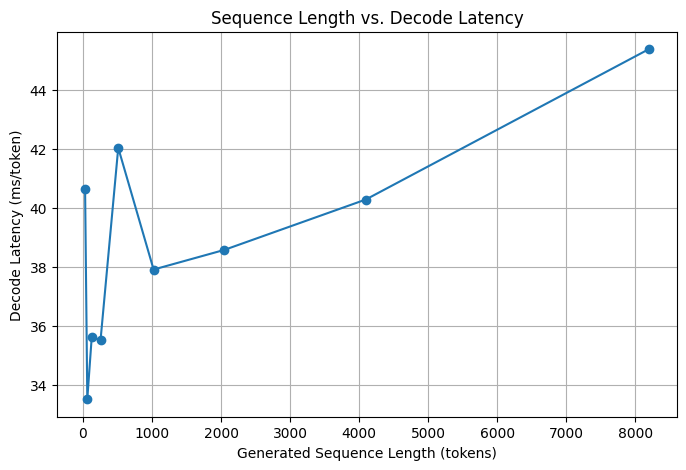

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    sequence_lengths,
    latencies,
    marker="o"
)

plt.xlabel("Generated Sequence Length (tokens)")
plt.ylabel("Decode Latency (ms/token)")
plt.title("Sequence Length vs. Decode Latency")
plt.grid(True)

plt.show()

In [ ]:
num_params = model.num_parameters()

num_layers = model.config.num_hidden_layers
hidden_size = model.config.hidden_size
prompt_length = inputs["input_ids"].shape[1]

compute = []

for length in sequence_lengths:

    #O(N)
    model_flops = 2 * num_params * length

    #O(N^2), but component is smaller than parameter component, so graph will prob stay relatively linear for the tested range
    attention_flops = (
        4 * num_layers * hidden_size *
        (length * prompt_length + length * (length + 1) / 2)
    )

    estimated_flops = model_flops + attention_flops

    compute.append(estimated_flops)

    print(
        f"{length} tokens: "
        f"{estimated_flops:.3e} FLOPs"
    )

32 tokens: 2.059e+11 FLOPs
64 tokens: 4.121e+11 FLOPs
128 tokens: 8.256e+11 FLOPs
256 tokens: 1.657e+12 FLOPs
512 tokens: 3.336e+12 FLOPs
1024 tokens: 6.763e+12 FLOPs
2048 tokens: 1.389e+13 FLOPs
4096 tokens: 2.922e+13 FLOPs
8192 tokens: 6.420e+13 FLOPs


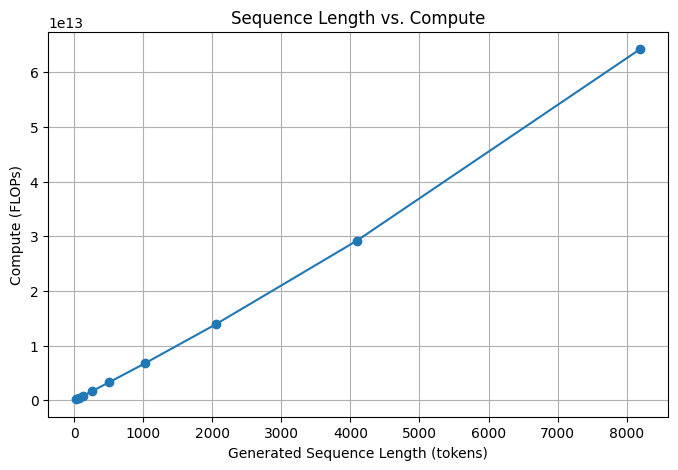

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    sequence_lengths,
    compute,
    marker="o"
)

plt.xlabel("Generated Sequence Length (tokens)")
plt.ylabel("Compute (FLOPs)")
plt.title("Sequence Length vs. Compute")
plt.ticklabel_format(
    axis="y",
    style="sci",
    scilimits=(0, 0)
)

plt.grid(True)
plt.show()

In [ ]:
num_layers = model.config.num_hidden_layers
num_kv_heads = model.config.num_key_value_heads
head_dim = model.config.head_dim
bytes_per_element = model.dtype.itemsize

prompt_length = inputs["input_ids"].shape[1]

memory = []

for length in sequence_lengths:

    total_tokens = prompt_length + length

    memory_bytes = (
        2
        * num_layers
        * num_kv_heads
        * head_dim
        * total_tokens
        * bytes_per_element
    )

    memory_mib = memory_bytes / (1024 ** 2)

    memory.append(memory_mib)

    print(f"{total_tokens} cached tokens: {memory_mib:.3f} MiB")

39 cached tokens: 4.266 MiB
71 cached tokens: 7.766 MiB
135 cached tokens: 14.766 MiB
263 cached tokens: 28.766 MiB
519 cached tokens: 56.766 MiB
1031 cached tokens: 112.766 MiB
2055 cached tokens: 224.766 MiB
4103 cached tokens: 448.766 MiB
8199 cached tokens: 896.766 MiB


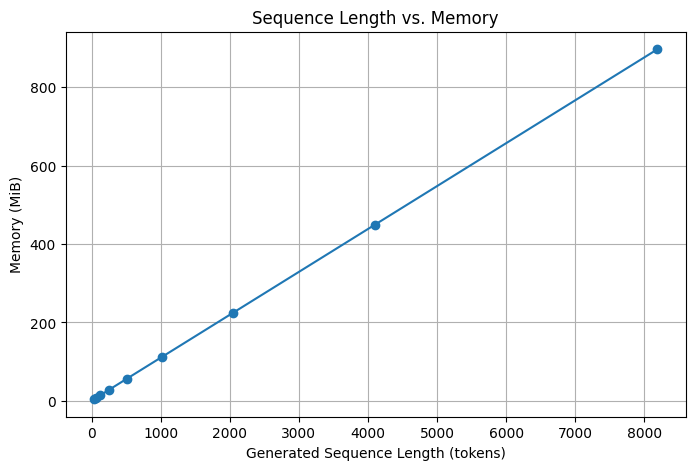

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    sequence_lengths,
    memory,
    marker="o"
)

plt.xlabel("Generated Sequence Length (tokens)")
plt.ylabel("Memory (MiB)")
plt.title("Sequence Length vs. Memory")
plt.grid(True)

plt.show()